# Clean file with modules

In [1]:
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(parent_dir)
parent_dir1 = os.path.abspath(os.path.join(parent_dir, '..'))
sys.path.append(parent_dir1)

import pytorch_lightning as pl
from pytorch_lightning.loggers import WandbLogger
from torch import nn
import torch.nn.functional as F
from simspice.data.SproutDataset_ONeS import SproutDataset
from torch.utils.data import DataLoader
from pytorch_lightning.callbacks import ModelCheckpoint
import torch
import numpy as np
import matplotlib.pyplot as plt
from cuml.cluster.hdbscan import HDBSCAN

import matplotlib.pyplot as plt
from lightly.loss import NTXentLoss

import simspice.utils.inverse_mapping_functions as imf
import simspice.models.SimSiam_Architecture_ONeS as SA
import wandb
#import umap.umap_ as umap
import tqdm
from datetime import datetime

plt.rcParams['image.origin'] = 'lower'

BATCH_SIZE = 128

In [2]:
simspice = "/d0/tvaresano/SimSPICE/"

In [3]:
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

In [11]:
dataset_path = simspice+"spectra_Feb2023_ONeS.nc"

dataset = SproutDataset(dataset_path=dataset_path,
    augmentation_type="single",
    csv_files=simspice + "L2_names.csv",
    normalization_eps=1e-8,
    shift_range=(-0.4, 0.4),
    sigma_shift=0.1, add_noise=True,
    background_range=(-.02, 0.02),
    add_background=False,
    max_augmentation_attempts=12,
    return_intensity_label=True)

dataset_none = SproutDataset(dataset_path=simspice+"spectra_9Jan2023_ONeS.nc",
    augmentation_type=None, csv_files=simspice + "L2_names.csv",)

dataloader = DataLoader(dataset,
    batch_size=BATCH_SIZE,
    shuffle=True, drop_last=True,
    num_workers=0, pin_memory=torch.cuda.is_available())

In [5]:
id = 'Simsiam_two_ch_norm_40epoch'

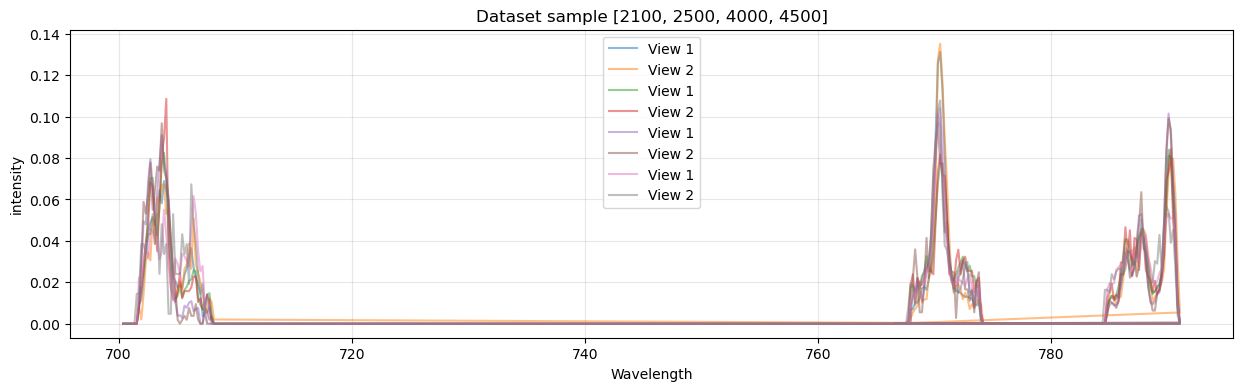

In [34]:
sample_indexs = [2100,2500,4000,4500]

wavelength = dataset.all_spectra.isel(index=sample_indexs[0])["wvl"].values
plt.figure(figsize=(15, 4))
for x in sample_indexs:
    view_1, view_2, m = dataset[x]
    view_1 = view_1.squeeze().numpy()
    view_2 = view_2.squeeze().numpy()
    plt.plot(wavelength, view_1[0,:], label="View 1", alpha=0.5)
    plt.plot(wavelength, view_2[0,:], label="View 2", alpha=0.5)
plt.xlabel("Wavelength")
plt.ylabel("intensity")#, plt.ylim(-.1,1.)
plt.title(f"Dataset sample {sample_indexs}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
batch = next(iter(dataloader))

view1, view2 = batch[:2]

print("View 1:", view1.shape)
print("View 2:", view2.shape)

View 1: torch.Size([128, 2, 121])
View 2: torch.Size([128, 2, 121])


## Train model

In [9]:
epoch_nbr = 40

model = SA.SpectralSimSiam(
    in_channels=2,
    backbone_embedding_dim=128,
    projection_hidden_dim=256,
    projection_output_dim=256,
    prediction_hidden_dim=128,
    learning_rate=3e-4,
    maximum_epochs=epoch_nbr,
    max_augmentation_attempts=5
)

accelerator = "gpu" if torch.cuda.is_available() else "cpu"

wandb_logger = WandbLogger(project="runs_single_augmentation_ONeS", name=f"{id}_{datetime.today().strftime('%Y-%m-%d')}", log_model=True)

trainer = pl.Trainer(max_epochs=epoch_nbr, devices=1, accelerator=accelerator, logger=wandb_logger)
trainer.fit(model=model, train_dataloaders=dataloader)

/d0/tvaresano/.conda/envs/simspice/lib/python3.13/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/d0/tvaresano/.conda/envs/simspice/lib/python3.13/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
You are using a CUDA device ('NVIDIA A100 80GB PCIe') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]

  | Name            | Type                     | Params | Mode 
---------------------------------------------------------------------
0 | backbone        | SpectralCNNTransformer   | 800 K  | train
1 | projection_head | SimSiamProjectionHead    | 164 K  | train
2 | prediction_head | SimSiamPredictionHead    | 66.0 K | train
3 | criterion       | NegativeCosineSimilarity | 0      | train
---------------------------------------------------------------------
1.0 M     Trainable params
0         Non-trainable params
1.0 M     Total params
4.127     Total estimated model params size (MB)
97        Modules in train mode
0         Modules in eval mode
/d0/tvaresano/.conda/envs/simspice/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to

Epoch 39: 100%|██████████| 907/907 [02:49<00:00,  5.35it/s, v_num=up5s, train_loss_step=-0.99, train_loss_epoch=-0.988] 

`Trainer.fit` stopped: `max_epochs=40` reached.


Epoch 39: 100%|██████████| 907/907 [02:49<00:00,  5.34it/s, v_num=up5s, train_loss_step=-0.99, train_loss_epoch=-0.988]


-------------------------------------------------------------------

## Extract the embeddings and normalize them (L2)

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
model.eval()

outputs = []

with torch.no_grad():
    for i in tqdm.tqdm(range(len(dataset_none))):
        spec = dataset_none[i].unsqueeze(0).to(device)
        embedding = model.encode(spec)
        embedding = F.normalize(embedding, p=2, dim=-1)
        outputs.append(embedding.squeeze(0).cpu().numpy())

stacked_outputs = np.stack(outputs, axis=0)
print(stacked_outputs.shape)

100%|██████████| 116160/116160 [05:33<00:00, 348.63it/s]


(116160, 128)


In [ ]:
# checkpoint = "C:\\Users\\tania\Documents\CU Boulder\CU Alpine\models_ckpts\single_epoch=4-step=45750.ckpt"
# dataset_none = SproutDataset(dataset_path=dataset_path, augmentation_type=None)
# outputs = SA.run_model(checkpoint, dataset_none)

In [13]:
stacked_outputs = np.stack(outputs).squeeze()
print(stacked_outputs.shape)
np.save(simspice+f'notebooks/jobs/model_outputs/stacked_outputs_single_9Jan23_{id}.npy', stacked_outputs)

(116160, 128)


In [ ]:
# stacked_outputs = np.load(simspice+f'notebooks/jobs/model_outputs/stacked_outputs_single_allJan23_{id}.npy')
stacked_outputs = np.load(simspice+'notebooks/jobs/model_outputs/stacked_outputs_single_9Jan23_Simsiam_norm_gain0.05-7_gauss_distrib0.1_80epoch.npy')

## Reducing dimensionality

In [15]:
from cuml.manifold import UMAP
from sklearn.preprocessing import StandardScaler

In [16]:
stacked_outputs.shape[0]//imf.SIZE_CROPPED_MAP

1

In [17]:
# Shape: (number_of_spectra, 256)
X_umap_dict = {}
umap_cluster = UMAP(n_components=25, n_neighbors=100, min_dist=0.0, metric="cosine", random_state=42)
for a in tqdm.tqdm(range(stacked_outputs.shape[0]//imf.SIZE_CROPPED_MAP)):
    X = np.asarray(stacked_outputs, dtype=np.float32)[116160*a:116160*(a+1)]  ## stacked_outputs
    # Standardize the embedding dimensions
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    X_umap_cluster = umap_cluster.fit_transform(X_scaled)
    X_umap_dict[a] = X_umap_cluster
    # print(X_umap_cluster.shape)

[2026-11-16 14:34:18.196] [CUML] [info] build_algo set to brute_force_knn because random_state is given


100%|██████████| 1/1 [00:03<00:00,  3.31s/it]


In [18]:
# xs = [10,15,50,100,200,300]
# ys = [10,15,20,100,200]
xs = [50,100,200,300,400,500]
ys = [10,15,20,100,200]
# cluster_print_noise_fraction(xs, ys, X=X_umap_cluster)
# plot_cluster_umap2D(xs,ys,n_neighbors=30)

## Clustering UMAP + normalized embeddings

In [19]:
xs = [200,300,400,500]
ys = [10,15,20,100,200]
for x in tqdm.tqdm(xs):
    for y in ys:
        clusterer = HDBSCAN(min_cluster_size=x, min_samples=y, metric='euclidean') # <=> cosine?
        # clusterer.fit(stacked_outputs) 
        clusterer.fit(X_umap_dict[0]) 
        labels = clusterer.labels_
        np.save(simspice+f'notebooks/jobs/clustering_outputs/minclus{x}_minsamp{y}_MgNe.npy', labels)

100%|██████████| 4/4 [00:54<00:00, 13.68s/it]


In [20]:
labels_UMAP = {}
for x in xs:
    for y in ys:
        labels = np.load(simspice+f'notebooks/jobs/clustering_outputs/minclus{x}_minsamp{y}_MgNe.npy')
        labels_UMAP[f"{x},{y}"] = labels

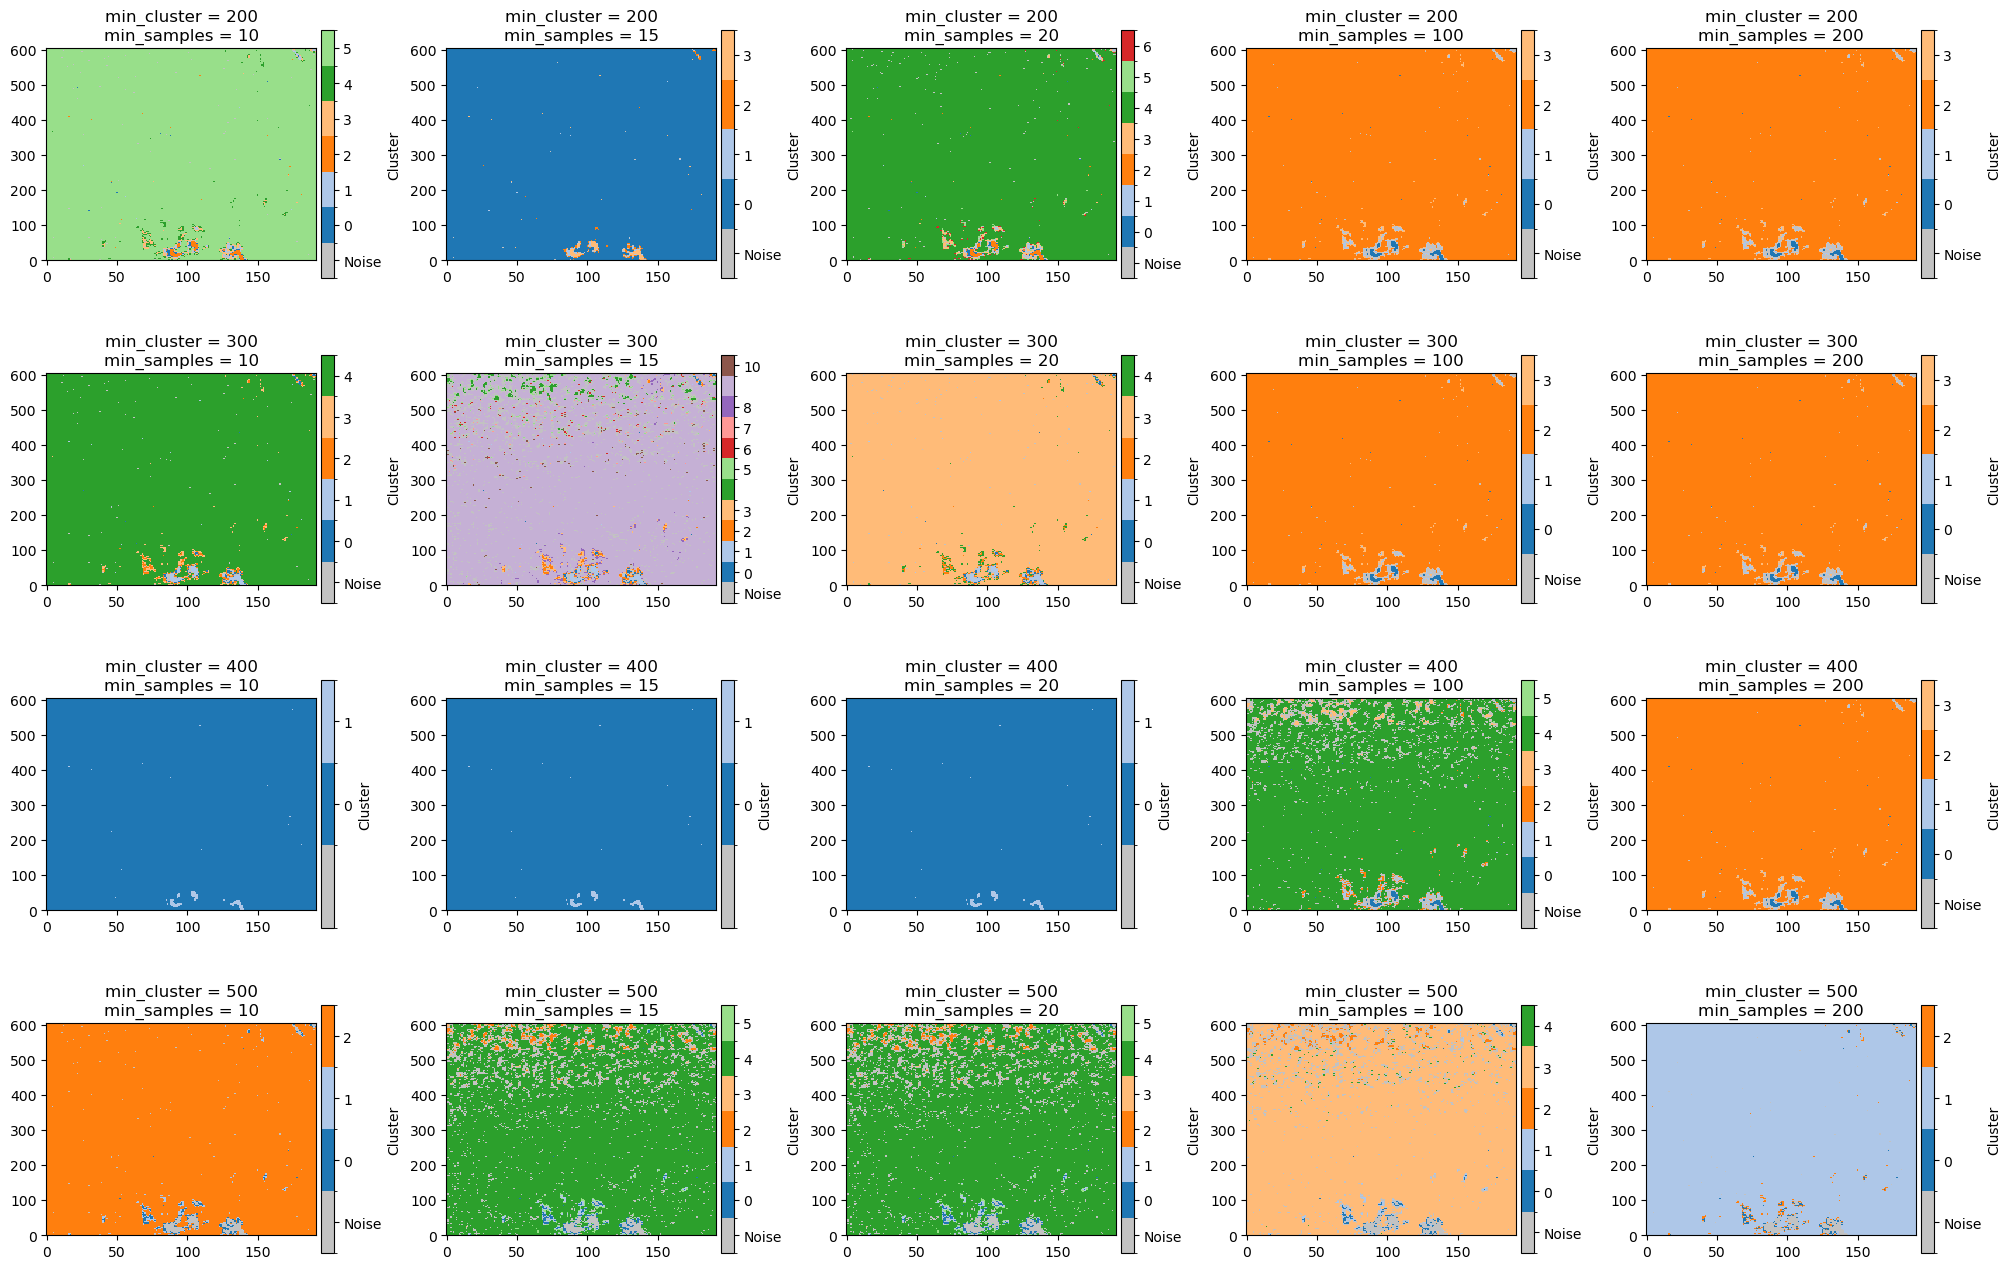

In [24]:
########### FOR ONE FILE ######################
cluster_ids, cluster_cmap, cluster_norm = (imf.make_cluster_style(labels_UMAP["300,15"], cmap='tab20'))
c=0
fig, axes = plt.subplots(4, 5, figsize=(20, 13), constrained_layout=True)
for x in xs:
    for y in ys:
        ax = axes.flat[c]
        c+=1
        noise_count = np.sum(labels_UMAP[f"{x},{y}"] == -1)
        noise_percent = 100 * np.mean(labels_UMAP[f"{x},{y}"] == -1)
        # print(f"{x}, {y} -- Noise: {noise_count} pixels ({noise_percent:.3f}%)")
        imf.map_clusters(labels_UMAP[f"{x},{y}"], dataset_path=simspice+'spectra_9Jan2023_MgNe.nc', selected_clusters=None, ax=ax, colormap='tab20')
        ax.set_title(f"min_cluster = {x}\nmin_samples = {y}")

Cluster -1: 836 samples
Cluster 0: 339 samples
Cluster 1: 402 samples
Cluster 2: 742 samples
Cluster 3: 113088 samples
Cluster 4: 753 samples


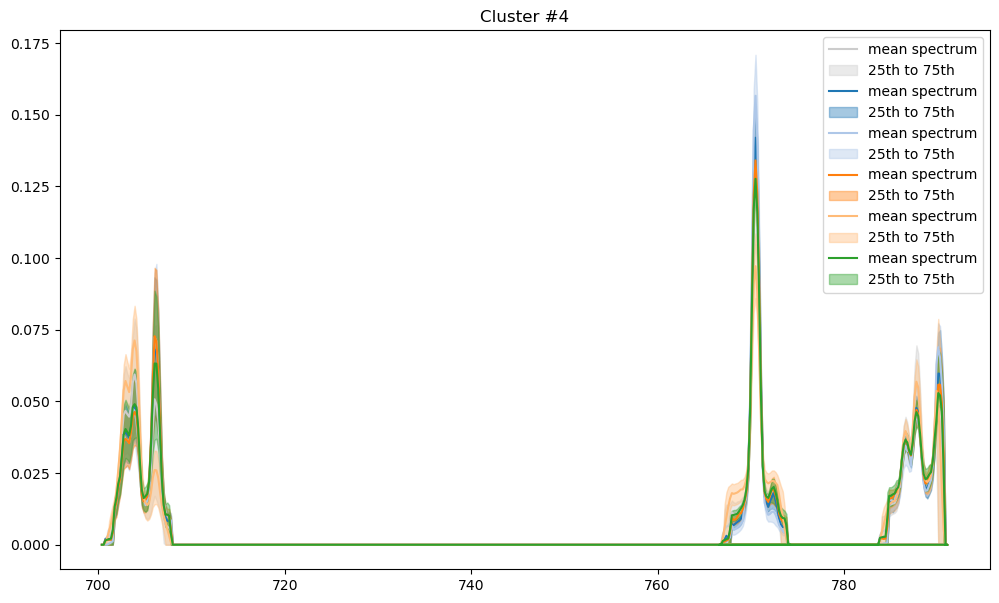

In [27]:
common_wvl = [700.3833769, 700.5784109, 700.7734449, 700.9684789, 701.1635129, 
            701.3585469, 701.5535809, 701.7486149, 701.9436489, 702.1386829, 702.3337169, 
            702.5287509, 702.7237849, 702.9188189, 703.1138529, 703.3088869, 703.5039209, 
            703.6989549, 703.8939889, 704.0890229, 704.2840569, 704.4790909, 704.6741249, 
            704.8691589, 705.0641929, 705.2592269, 705.4542609, 705.6492949, 705.8443289, 
            706.0393629, 706.2343969, 706.4294309, 706.6244649, 706.8194989, 707.0145329, 
            707.2095669, 707.4046009, 707.5996349, 707.7946689, 707.9897029, 708.1847369, 
            783.4678609, 783.6628949, 783.8579289, 784.0529629, 784.2479969, 784.4430309, 
            784.6380649, 784.8330989, 785.0281329, 785.2231669, 785.4182009, 785.6132349, 
            785.8082689, 786.0033029, 786.1983369, 786.3933709, 786.5884049, 786.7834389, 
            786.9784729, 787.1735069, 787.3685409, 787.5635749, 787.7586089, 787.9536429, 
            788.1486769, 788.3437109, 788.5387449, 788.7337789, 788.9288129, 789.1238469, 
            789.3188809, 789.5139149, 789.7089489, 789.9039829, 790.0990169, 790.2940509, 
            790.4890849, 790.6841189, 790.8791529, 791.0741869, 766.5974199, 766.7924539, 
            766.9874879, 767.1825219, 767.3775559, 767.5725899, 767.7676239, 767.9626579, 
            768.1576919, 768.3527259, 768.5477599, 768.7427939, 768.9378279, 769.1328619, 
            769.3278959, 769.5229299, 769.7179639, 769.9129979, 770.1080319, 770.3030659, 
            770.4980999, 770.6931339, 770.8881679, 771.0832019, 771.2782359, 771.4732699, 
            771.6683039, 771.8633379, 772.0583719, 772.2534059, 772.4484399, 772.6434739, 
            772.8385079, 773.0335419, 773.2285759, 773.4236099, 773.6186439, 773.8136779, 
            774.0087119, 774.2037459]
                            
labels = labels_UMAP["300,20"]
cluster_ids = np.unique(labels)

fig, ax = plt.subplots(figsize=(12, 7))
for cluster_id in cluster_ids:
    cluster_color = cluster_cmap(cluster_norm(cluster_id))
    imf.plot_average_spectra_cluster(
        labels=labels,
        stacked_outputs=stacked_outputs,
        chosen_cluster=int(cluster_id),
        dataset=dataset_none, ax=ax,
        log_scale=False, color=cluster_color,
        dataset_path=simspice + "spectra_9Jan2023_ONeS.nc",
        wvl=common_wvl   )

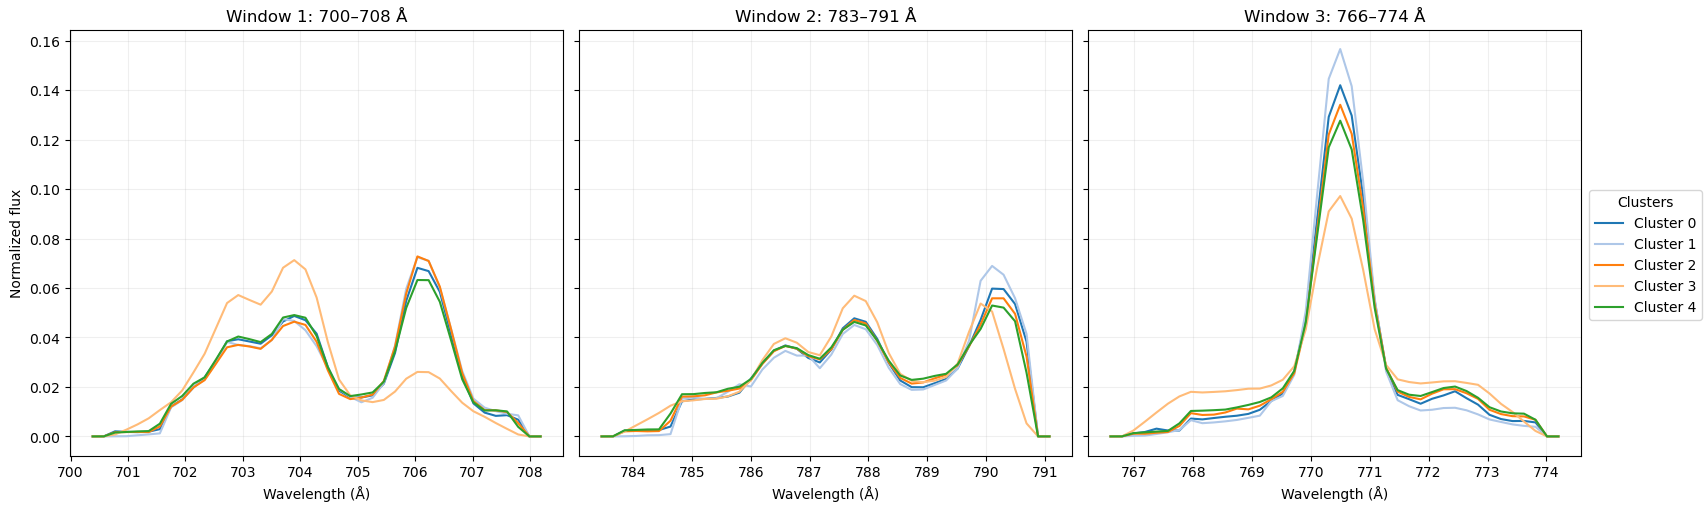

In [28]:
labels = np.asarray(labels_UMAP["300,20"])
wvl = np.asarray(common_wvl)

# Extract normalized spectral-shape channel
spectra = np.stack([dataset_none[i][0].detach().cpu().numpy() for i in range(len(dataset_none))])

# Define the three windows
windows = [(slice(0, 41), "Window 1: 700–708 Å"),
    (slice(41, 81), "Window 2: 783–791 Å"),
    (slice(81, 121), "Window 3: 766–774 Å")]

cluster_ids = np.unique(labels)
cluster_ids = cluster_ids[cluster_ids != -1]  # Exclude noise

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True, constrained_layout=True)

for cluster_id in cluster_ids:

    mask = labels == cluster_id
    mean_spectrum = spectra[mask].mean(axis=0)
    color = cluster_cmap(cluster_norm(cluster_id))

    for ax, (sl, title) in zip(axes, windows):
        ax.plot(wvl[sl], mean_spectrum[sl], color=color, linewidth=1.5, label=f"Cluster {cluster_id}")

for ax, (_, title) in zip(axes, windows):
    ax.set_title(title)
    ax.set_xlabel("Wavelength (Å)")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Normalized flux")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside right", title="Clusters")

plt.show()

## Without UMAP

In [30]:
xs = [200,300,400,500]
ys = [10,15,20,100,200]
for x in xs:
    for y in tqdm.tqdm(ys):
        clusterer = HDBSCAN(min_cluster_size=x, min_samples=y, metric='euclidean') # <=> cosine?
        clusterer.fit(stacked_outputs)   # stacked outputs
        labels = clusterer.labels_
        np.save(simspice+f'notebooks/jobs/clustering_outputs/minclus{x}_minsamp{y}_MgNe.npy', labels)

100%|██████████| 5/5 [00:09<00:00,  1.97s/it]


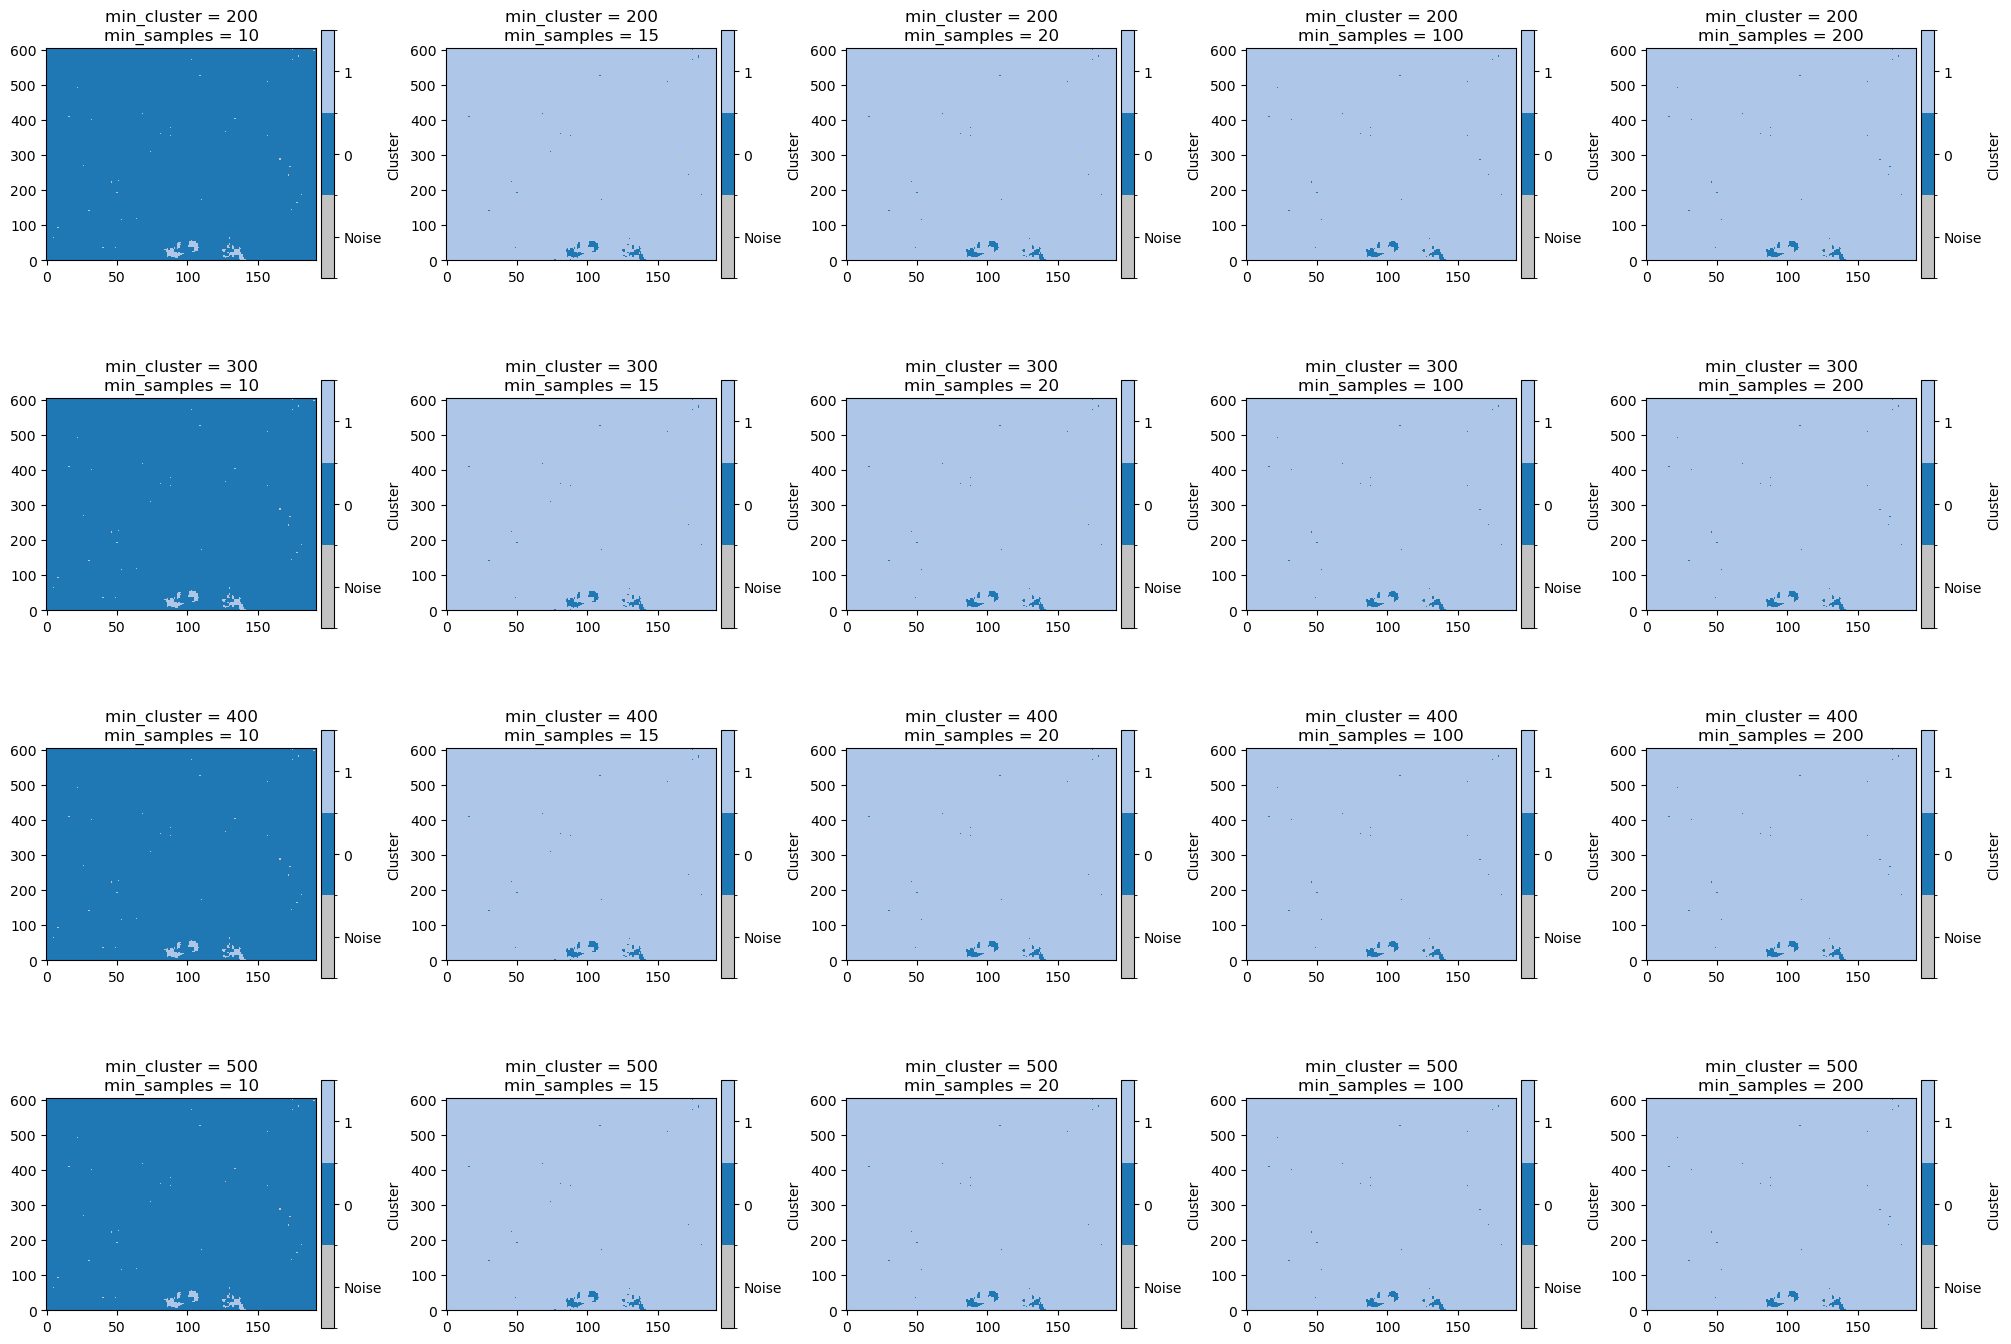

In [31]:
c=0
fig, axes = plt.subplots(4, 5, figsize=(20, 14), constrained_layout=True)
for x in xs:
    for y in ys:
        ax = axes.flat[c]
        c+=1
        labels = np.load(simspice+f'notebooks/jobs/clustering_outputs/minclus{x}_minsamp{y}_MgNe.npy')
        imf.map_clusters(labels, dataset_path=simspice+'spectra_Feb2023.nc', selected_clusters=None, ax=ax)
        ax.set_title(f"min_cluster = {x}\nmin_samples = {y}")
# fig.suptitle('Feb23_Fulltrained_single32')

# Post analysis

In [ ]:
np.arange(0,len(np.unique(labels_UMAP["400,15"])), dtype=int)

In [ ]:
labels_clust = {}
for x in xs:
    for y in ys:
        labels = np.load(simspice+f'notebooks/jobs/clustering_outputs/minclus{x}_minsamp{y}_MgNe.npy')
        labels_clust[f"{x},{y}"] = labels
cluster_ids, cluster_cmap, cluster_norm = (imf.make_cluster_style(labels_clust["200,15"], cmap='tab20'))

In [ ]:
labels = labels_clust["300,20"]
cluster_ids = np.unique(labels)

fig, ax = plt.subplots(figsize=(12, 7))
for cluster_id in cluster_ids:
    cluster_color = cluster_cmap(cluster_norm(cluster_id))
    imf.plot_average_spectra_cluster(
        labels=labels,
        stacked_outputs=stacked_outputs,
        chosen_cluster=int(cluster_id),
        dataset=dataset_none, ax=ax,
        log_scale=False, color=cluster_color,
        dataset_path=simspice + "spectra_9Jan2023_MgNe.nc",
        wvl=common_wvl   )

In [ ]:
cluster_ids

In [ ]:
fig, axes = plt.subplots(3,3,figsize=(16, 10))
axes = axes.ravel()
for cluster_id in cluster_ids:
    cluster_color = cluster_cmap(cluster_norm(cluster_id))
    imf.plot_average_spectra_cluster(
        labels=labels,
        stacked_outputs=stacked_outputs,
        chosen_cluster=int(cluster_id),
        dataset=dataset_none, ax=axes[cluster_id+1],
        log_scale=True, color=cluster_color,
        dataset_path=simspice + "spectra_9Jan2023_MgNe.nc",
        wvl=common_wvl   )
    axes[cluster_id+1].set_ylim(.02,1)
    axes[cluster_id+1].grid(True, alpha=0.4)

In [ ]:
plt.figure(figsize=(15,5))
ax1 = plt.subplot(1,2,1)
imf.map_clusters(labels_UMAP[f"300,20"], dataset_path=simspice+'spectra_9Jan2023_MgNe.nc', selected_clusters=None, ax=ax1, colormap='tab20', contour=False,data_dir=simspice+"data_L2/9Jan2023/",)

ax2 = plt.subplot(1,2,2)
imf.map_clusters(labels_UMAP[f"300,20"], dataset_path=simspice+'spectra_9Jan2023_MgNe.nc', selected_clusters=None, ax=ax2, colormap='tab20', contour=True,data_dir=simspice+"data_L2/9Jan2023/",)
plt.show()

In [ ]:
imf.map_item_map(30245,
                 dataset= "dataset_Jan_2023_NeMg_20files.nc",
                 plot=True,
                 data_dir = 'data_L2/SPICE_data_Jan2023/')
plt.show()